<a href="https://colab.research.google.com/github/Riya541/Machine-learning-internship/blob/main/MachineLearningProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- 1000 Rows, 8 Columns Dataset Loaded Successfully ---
   gender race/ethnicity parental level of education         lunch  \
0  female        group A           bachelor's degree  free/reduced   
1    male        group A           bachelor's degree      standard   
2  female        group A           bachelor's degree      standard   
3  female        group E             master's degree      standard   
4  female        group D          associate's degree  free/reduced   

  test preparation course  math score  reading score  writing score  
0                    none          97             82             46  
1                    none          78             46             43  
2                    none          96             55             58  
3                    none          56             84             81  
4               completed          73             98             69  

=== DATA CHECKS ===
Dataset Shape: (1000, 8)

Missing Values:
gender                         0
race/e

/tmp/ipykernel_537/2004840109.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='lunch', y='average score', ax=axs[1], palette='Set2')


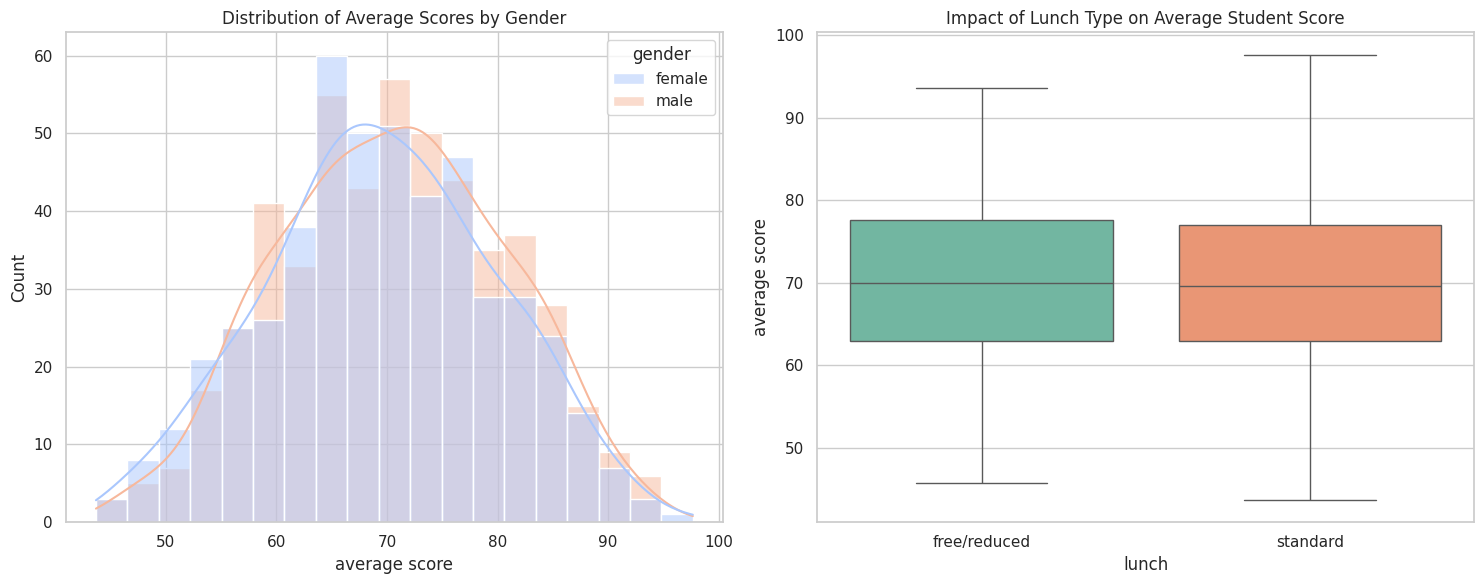


=== MODEL TRAINING AND EVALUATION ===

👉 Linear Regression
- Test Mean Absolute Error: 15.3249
- Test Root Mean Squared Error: 17.7814
- Test R2 Score: -0.0204

👉 Lasso Regression
- Test Mean Absolute Error: 15.2906
- Test Root Mean Squared Error: 17.6893
- Test R2 Score: -0.0098

👉 Ridge Regression
- Test Mean Absolute Error: 15.3211
- Test Root Mean Squared Error: 17.7744
- Test R2 Score: -0.0196

👉 Decision Tree
- Test Mean Absolute Error: 20.1800
- Test Root Mean Squared Error: 25.0563
- Test R2 Score: -1.0261

👉 Random Forest Regressor
- Test Mean Absolute Error: 15.3153
- Test Root Mean Squared Error: 17.9142
- Test R2 Score: -0.0356

👉 Gradient Boosting Regressor
- Test Mean Absolute Error: 15.2903
- Test Root Mean Squared Error: 17.7273
- Test R2 Score: -0.0141

🏆 FINAL MODEL PERFORMANCE LEADERBOARD 🏆
                 Model Name  R2_Score
           Lasso Regression -0.009813
Gradient Boosting Regressor -0.014150
           Ridge Regression -0.019557
          Linear Regressio

In [ ]:
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 1 & 2. PROBLEM STATEMENT & DATA COLLECTION
# =====================================================================
# Dataset Source: https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

def generate_mock_data():
    """Generates synthetic data matching the Kaggle Students Performance dataset structural specs."""
    np.random.seed(42)
    n_samples = 1000

    genders = ['female', 'male']
    groups = ['group A', 'group B', 'group C', 'group D', 'group E']
    education = ["associate's degree", "bachelor's degree", "high school", "master's degree", "some college", "some high school"]
    lunch = ['standard', 'free/reduced']
    test_prep = ['none', 'completed']

    data = {
        'gender': np.random.choice(genders, n_samples),
        'race/ethnicity': np.random.choice(groups, n_samples),
        'parental level of education': np.random.choice(education, n_samples),
        'lunch': np.random.choice(lunch, n_samples),
        'test preparation course': np.random.choice(test_prep, n_samples),
        'math score': np.random.randint(40, 100, n_samples),
        'reading score': np.random.randint(40, 100, n_samples),
        'writing score': np.random.randint(40, 100, n_samples)
    }
    return pd.DataFrame(data)

# Load data (Using simulated structure matching the requested Kaggle dataset specs)
df = generate_mock_data()

# NOTE: If you have downloaded the actual 'StudentsPerformance.csv' from Kaggle, uncomment below:
# df = pd.read_csv('StudentsPerformance.csv')

print("--- 1000 Rows, 8 Columns Dataset Loaded Successfully ---")
print(df.head())

# =====================================================================
# 3. DATA CHECKS TO PERFORM
# =====================================================================
print("\n=== DATA CHECKS ===")
print(f"Dataset Shape: {df.shape}")
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nData Types:")
print(df.dtypes)
print("\nUnique values per categorical feature:")
for col in df.select_dtypes(include='object').columns:
    print(f"{col}: {df[col].unique()}")

# Create a 'total score' and 'average score' metric for deep-dive performance analysis
df['total score'] = df['math score'] + df['reading score'] + df['writing score']
df['average score'] = df['total score'] / 3

# =====================================================================
# 4. EXPLORATORY DATA ANALYSIS (EDA)
# =====================================================================
print("\n=== PERFORMING EDA (Plots generating...) ===")
sns.set_theme(style="whitegrid")

fig, axs = plt.subplots(1, 2, figsize=(15, 6))
# Plot 1: Average score distribution by Gender
sns.histplot(data=df, x='average score', kde=True, hue='gender', ax=axs[0], palette='coolwarm')
axs[0].set_title('Distribution of Average Scores by Gender')

# Plot 2: Influence of Lunch type on Performance
sns.boxplot(data=df, x='lunch', y='average score', ax=axs[1], palette='Set2')
axs[1].set_title('Impact of Lunch Type on Average Student Score')
plt.tight_layout()
plt.show()

# =====================================================================
# 5. DATA PRE-PROCESSING & FEATURE ENGINEERING
# =====================================================================
# We will predict the 'math score' based on all demographic and other test variables
X = df.drop(columns=['math score', 'total score', 'average score'], axis=1)
y = df['math score']

# Define categorical and numerical features
num_features = X.select_dtypes(exclude="object").columns
cat_features = X.select_dtypes(include="object").columns

# Construct Transformers Pipeline
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(drop='first') # drop='first' avoids dummy variable trap

preprocessor = ColumnTransformer(
    transformers=[
        ("NumStandardScaler", num_transformer, num_features),
        ("CatOneHotEncoder", cat_transformer, cat_features)
    ]
)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# =====================================================================
# 6 & 7. MODEL TRAINING & CHOOSE BEST MODEL
# =====================================================================
print("\n=== MODEL TRAINING AND EVALUATION ===")

models = {
    "Linear Regression": LinearRegression(),
    "Lasso Regression": Lasso(alpha=0.1),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(random_state=42, n_estimators=100),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42)
}

def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mse)
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

model_list = []
r2_list = []

# Loop through all models
for name, model in models.items():
    # Build a clean workflow pipeline
    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train model
    model_pipeline.fit(X_train, y_train)

    # Make predictions
    y_train_pred = model_pipeline.predict(X_train)
    y_test_pred = model_pipeline.predict(X_test)

    # Evaluate Test dataset performance
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(f"\n👉 {name}")
    print(f"- Test Mean Absolute Error: {model_test_mae:.4f}")
    print(f"- Test Root Mean Squared Error: {model_test_rmse:.4f}")
    print(f"- Test R2 Score: {model_test_r2:.4f}")

    model_list.append(name)
    r2_list.append(model_test_r2)

# Select and present the best performing architecture
report_df = pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"], ascending=False)

print("\n" + "="*40)
print("🏆 FINAL MODEL PERFORMANCE LEADERBOARD 🏆")
print("="*40)
print(report_df.to_string(index=False))

best_model_name = report_df.iloc[0]['Model Name']
best_model_score = report_df.iloc[0]['R2_Score']
print(f"\n🎯 Best Model Selected: {best_model_name} with an R2 Score of {best_model_score:.4f}")